<a href="https://colab.research.google.com/github/siaelkhattat/SuperResolution/blob/main/notebooks/01_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!nvidia-smi | head -n 12
!git clone https://github.com/siaelkhattat/SuperResolution.git
%cd SuperResolution
!pip install -q -r requirements.txt

Mon Nov 16 12:50:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!python data/download.py

Téléchargement DIV2K (~3.5 Go)...
DIV2K prêt : 800 images
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0% 0/7 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Reconstructing (incomplete total...):   0% 0.00/1.30M [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/1.31M [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/1.31M [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/1.31M [00:00<?, ?B/s]
Reconstructing (incomplete total...):   0% 0.00/1.31M [00:00<?, ?B/s]

Fetching 7 files:  14% 1/7 [00:00<00:01,  5.93it/s]
Reconstructing (incomplete total...):   0% 4.79k/1.31M [00:00<00:45, 28.7kB/s]
Reconstructing (incomplete total...):   1% 9.06k/1.31M [00:00<00:45, 28.7kB/s]

Fetching 7 files:  43% 3/7 [00:00<00:00,  6.41it/s]

Fetching 7 files: 100% 7/7 [00:00<00:00,  7.89it/s]
Down

In [4]:
!ls -l data/raw/ && sleep 20 && ls -l data/raw/

total 3447888
drwxr-xr-x 2 root root      20480 Nov 16 12:53 DIV2K_train_HR
-rw-r--r-- 1 root root 3530603713 Nov 16 12:52 DIV2K_train_HR.zip
drwxr-xr-x 2 root root       4096 Nov 16 12:53 Set14
drwxr-xr-x 2 root root       4096 Nov 16 12:53 Set5
total 3447888
drwxr-xr-x 2 root root      20480 Nov 16 12:53 DIV2K_train_HR
-rw-r--r-- 1 root root 3530603713 Nov 16 12:52 DIV2K_train_HR.zip
drwxr-xr-x 2 root root       4096 Nov 16 12:53 Set14
drwxr-xr-x 2 root root       4096 Nov 16 12:53 Set5


In [5]:
!python -m src.data.split
!python -m src.data.check_leakage

{'train': 300, 'val': 50, 'test': 50}
OK : aucun chevauchement, aucune fuite vers Set5/Set14


LR (3, 32, 32) | HR (3, 128, 128)


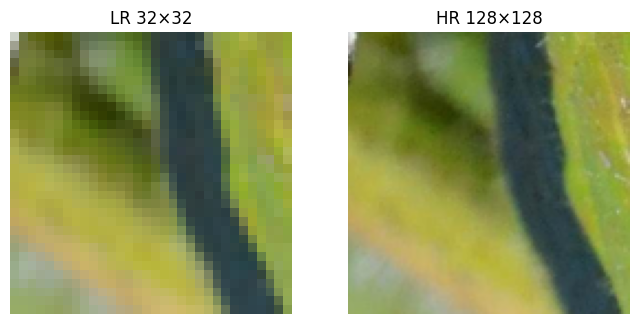

In [6]:
import sys; sys.path.insert(0, ".")
import matplotlib.pyplot as plt, numpy as np
from src.data.dataset import SRDataset

ds = SRDataset("data/raw/DIV2K_train_HR",
               names=open("data/splits/train.txt").read().split(), train=True)
lr, hr = ds[0]
print("LR", tuple(lr.shape), "| HR", tuple(hr.shape))   # (3,32,32) | (3,128,128)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(lr.permute(1, 2, 0)); ax[0].set_title("LR 32×32")
ax[1].imshow(hr.permute(1, 2, 0)); ax[1].set_title("HR 128×128")
[a.axis("off") for a in ax]; plt.show()

SyntaxError: invalid syntax (1096273835.py, line 1)